#  Build the training dataset (Google Colab)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!rm -rf /content/s1lulc-repo
!unzip -q -o /content/drive/MyDrive/s1lulc-repo.zip -d /content
%cd /content/s1lulc-repo
!pip -q install -e ".[geo]" matplotlib

Mounted at /content/drive
/content/s1lulc-repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for s1lulc (pyproject.toml) ... done


In [ ]:
from pathlib import Path
SRC = Path("/content/drive/MyDrive/lulc_s1_data")
tifs = sorted(SRC.glob("*.tif"))
print(len(tifs), "GeoTIFFs found")
for t in tifs:
    print(f"  {t.name:40s} {t.stat().st_size / 1e6:7.1f} MB")

41 GeoTIFFs found
  andalusia_dry__r1-0.tif                    124.0 MB
  athens__r1-0.tif                           125.3 MB
  barcelona__r1-0.tif                        125.3 MB
  bardenas_bare__r1-0.tif                    124.9 MB
  beauce_farmland__r1-0.tif                  124.6 MB
  biebrza_wetland__r1-0.tif                  123.4 MB
  black_forest__r1-0.tif                     124.6 MB
  brittany_rural__r1-0.tif                   124.0 MB
  bucharest_plain__r1-0.tif                  125.0 MB
  budapest__r1-0.tif                         124.6 MB
  cairo_nile__r1-0.tif                       124.8 MB
  camargue_wetland__r1-0.tif                 123.7 MB
  castilla_dry__r1-0.tif                     123.4 MB
  copenhagen__r1-0.tif                       126.4 MB
  danube_delta__r1-0.tif                     125.0 MB
  donana_wetland__r1-0.tif                   124.3 MB
  finland_lakes__r1-0.tif                    125.8 MB
  flevoland_polder__r1-0.tif                 125.4 MB
  hungary_

## Build the dataset

In [ ]:
OUT = Path("/content/s1lulc_dataset")
!s1lulc build-dataset --src "{SRC}" --out "{OUT}"

2026-11-08 07:40:11,662 INFO s1lulc.data.build: processing pilot_urban_milan (train)
2026-11-08 07:40:23,810 INFO s1lulc.data.build: processing pilot_rural_ammersee (train)
2026-11-08 07:40:28,594 WARNING s1lulc.data.build: pilot_rural_ammersee: months with fewer than 3 passes (noisier composite): [2]
2026-11-08 07:40:32,118 INFO s1lulc.data.build: processing paris (train)
2026-11-08 07:40:38,876 INFO s1lulc.data.build: processing madrid (train)
2026-11-08 07:40:46,447 INFO s1lulc.data.build: processing warsaw (train)
2026-11-08 07:40:53,388 INFO s1lulc.data.build: processing athens (train)
2026-11-08 07:41:00,993 INFO s1lulc.data.build: processing beauce_farmland (train)
2026-11-08 07:41:10,634 INFO s1lulc.data.build: processing black_forest (train)
2026-11-08 07:41:16,804 INFO s1lulc.data.build: processing camargue_wetland (train)
2026-11-08 07:41:26,183 INFO s1lulc.data.build: processing lake_balaton (train)
2026-11-08 07:41:37,359 INFO s1lulc.data.build: processing po_delta (train)

## Dataset report

Quality checks


,region,split,ok,errors,warnings
0,pilot_urban_milan,train,True,NaN,NaN
1,pilot_rural_ammersee,train,True,NaN,months with fewer than 3 passes (noisier compo...
2,paris,train,True,NaN,NaN
3,madrid,train,True,NaN,NaN
4,warsaw,train,True,NaN,NaN
5,athens,train,True,NaN,NaN
6,beauce_farmland,train,True,NaN,NaN
7,black_forest,train,True,NaN,NaN
8,camargue_wetland,train,True,NaN,NaN
9,lake_balaton,train,True,NaN,NaN


Class distribution by split (%)


split,test,test_ood,train,val
class,,,,
bare_sparse,0.10,3.78,2.61,1.35
built_up,16.64,85.63,24.00,18.50
cropland,5.35,0.58,12.12,31.30
low_vegetation,8.89,1.01,20.71,11.52
tree_cover,62.37,6.23,27.34,13.31
water,6.41,2.75,10.18,6.97
wetland,0.24,0.02,3.04,17.04


Class distribution by region (%)


,region,split,tree_cover,low_vegetation,cropland,built_up,bare_sparse,water,wetland
0,pilot_urban_milan,train,23.29,6.95,7.13,62.02,0.33,0.28,0.00
1,pilot_rural_ammersee,train,37.56,17.91,4.56,3.61,0.01,36.10,0.25
2,paris,train,11.88,0.67,0.04,85.68,0.06,1.68,0.00
3,madrid,train,23.32,7.42,0.24,68.28,0.48,0.27,0.00
4,warsaw,train,40.27,4.14,0.20,52.10,0.21,2.98,0.11
5,athens,train,13.17,4.74,0.10,80.96,0.40,0.63,0.00
6,beauce_farmland,train,9.47,2.42,86.69,1.41,0.00,0.01,0.00
7,black_forest,train,63.71,34.57,0.66,1.04,0.00,0.01,0.00
8,camargue_wetland,train,1.47,8.99,1.96,0.11,4.97,53.45,29.04
9,lake_balaton,train,10.05,6.55,1.49,1.57,0.02,79.44,0.88


Median Sentinel-1 acquisitions per monthly composite


,region,split,m01,m02,m03,m04,m05,m06,m07,m08,m09,m10,m11,m12
0,pilot_urban_milan,train,16,11,16,15,16,15,16,14,15,15,15,14
1,pilot_rural_ammersee,train,7,2,6,10,11,9,10,9,10,10,10,9
2,paris,train,15,12,15,15,14,14,16,16,15,14,15,14
3,madrid,train,12,7,10,10,12,10,10,9,10,10,10,9
4,warsaw,train,19,19,21,20,20,20,21,21,20,20,18,18
5,athens,train,15,15,15,15,15,14,17,16,15,15,14,13
6,beauce_farmland,train,20,17,20,20,19,19,20,21,20,20,20,18
7,black_forest,train,19,15,18,20,21,19,20,19,20,20,20,17
8,camargue_wetland,train,19,18,21,20,19,18,19,20,20,20,20,18
9,lake_balaton,train,14,12,16,15,15,15,15,13,15,16,13,12


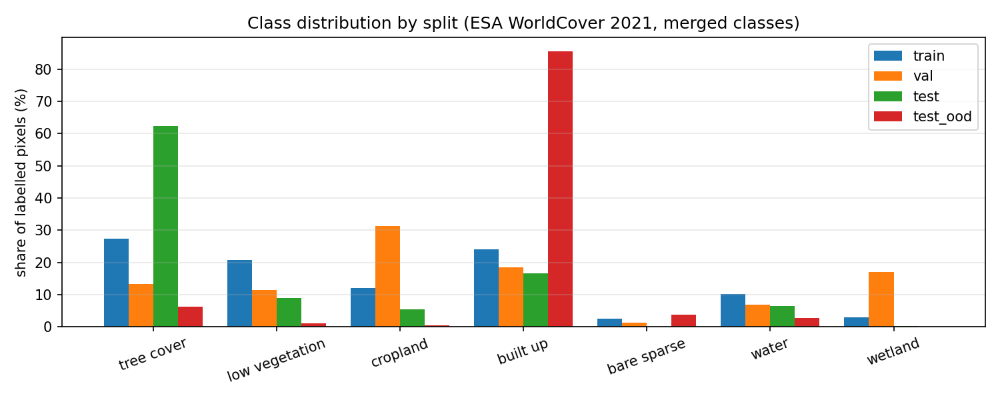

In [ ]:
import pandas as pd
from IPython.display import Image, display
R = OUT / "reports"
print("Quality checks"); display(pd.read_csv(R / "qc_summary.csv"))
print("Class distribution by split (%)")
dist = pd.read_csv(R / "class_distribution_by_split.csv")
display(dist.pivot(index="class", columns="split", values="percent").round(2))
print("Class distribution by region (%)"); display(pd.read_csv(R / "class_distribution_by_region.csv"))
print("Median Sentinel-1 acquisitions per monthly composite"); display(pd.read_csv(R / "passes_per_month.csv"))
display(Image(str(R / "class_distribution.png")))

## Visual check of every region (radar vs. label)




In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
D = OUT / "data"
meta = json.loads((D / "meta.json").read_text())
cmap = ListedColormap(meta["class_colors"])
regs = meta["regions"]
fig, axes = plt.subplots(len(regs), 3, figsize=(9, 3 * len(regs)))
for row, r in zip(np.atleast_2d(axes), regs):
    with np.load(D / r["file"]) as z:
        db, lab = z["db"].astype(np.float32), z["label"]
    row[0].imshow(db[0, 0], cmap="gray", vmin=-25, vmax=5); row[0].set_title(f"{r['name']} VV Jan")
    row[1].imshow(db[6, 0], cmap="gray", vmin=-25, vmax=5); row[1].set_title("VV Jul")
    row[2].imshow(np.ma.masked_equal(lab, 255), cmap=cmap, vmin=-0.5, vmax=6.5, interpolation="nearest")
    row[2].set_title(f"label ({r['split']})")
    for a in row: a.axis("off")
fig.tight_layout(); fig.savefig(R / "regions_overview.png", dpi=80); plt.show()

In [ ]:
!rm -rf /content/drive/MyDrive/s1lulc_dataset
!cp -r "{OUT}" /content/drive/MyDrive/s1lulc_dataset
!du -sh /content/drive/MyDrive/s1lulc_dataset/*

1.5G	/content/drive/MyDrive/s1lulc_dataset/data
5.6M	/content/drive/MyDrive/s1lulc_dataset/reports


In [ ]:
import os, json, shutil, getpass
token = getpass.getpass("Paste your Kaggle API token: ").strip()
user = input("Your Kaggle username (as in kaggle.com/<username>): ").strip().split()[0].lower()
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/access_token", "w") as f:
    f.write(token)
os.chmod("/root/.kaggle/access_token", 0o600)
os.environ["KAGGLE_API_TOKEN"] = token
!pip -q install -U kaggle
!kaggle datasets list --mine
shutil.copy("/content/drive/MyDrive/s1lulc-repo.zip", D / "s1lulc-repo.zip")
(D / "dataset-metadata.json").write_text(json.dumps({
    "title": "S1 LULC monthly composites 2021",
    "id": f"{user}/s1lulc-dataset",
    "licenses": [{"name": "CC-BY-4.0"}]}))
print("uploading as", f"{user}/s1lulc-dataset")
import subprocess
exists = subprocess.run(["kaggle", "datasets", "status", f"{user}/s1lulc-dataset"],
                        capture_output=True).returncode == 0
cmd = (["kaggle", "datasets", "version", "-p", str(D), "-m", "updated regions"] if exists
       else ["kaggle", "datasets", "create", "-p", str(D)])
print("updating existing dataset" if exists else "creating dataset")
subprocess.run(cmd, check=True)

Paste your Kaggle API token: ··········
Your Kaggle username (as in kaggle.com/<username>): mofi007
ref                     title                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------  -------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
mofi007/s1lulc-dataset  S1 LULC monthly composites 2021   926764978  2026-11-07 12:54:06.413000              0          0  0.25             
uploading as mofi007/s1lulc-dataset
updating existing dataset


CompletedProcess(args=['kaggle', 'datasets', 'version', '-p', '/content/s1lulc_dataset/data', '-m', 'updated regions'], returncode=0)

In [ ]:
!cd /content/drive/MyDrive/s1lulc_dataset && zip -q -r /content/reports.zip reports data/meta.json
from google.colab import files
files.download("/content/reports.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, getpass, subprocess
from google.colab import drive, files
drive.mount("/content/drive")
token = getpass.getpass("Kaggle API token: ").strip()
os.makedirs("/root/.kaggle", exist_ok=True)
open("/root/.kaggle/access_token", "w").write(token); os.chmod("/root/.kaggle/access_token", 0o600)
os.environ["KAGGLE_API_TOKEN"] = token
!pip -q install -U kaggle
!rm -rf /content/kout && mkdir /content/kout
!kaggle kernels output mofi007/notebook47081c6e75 -p /content/kout
!ls -lh /content/kout
!cp /content/kout/results.zip /content/drive/MyDrive/results.zip
!rm -rf /content/res && mkdir /content/res && unzip -q /content/kout/results.zip -d /content/res
!cd /content/res && rm -f /content/results_small.zip && zip -q -r /content/results_small.zip . -x "*.pt"
!ls -lh /content/results_small.zip /content/drive/MyDrive/results.zip
files.download("/content/results_small.zip")

Mounted at /content/drive
Kaggle API token: ··········
100% 87.5k/87.5k [00:00<00:00, 680kB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/confusion_test.png
100% 88.0k/88.0k [00:00<00:00, 764kB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/confusion_test_ood.png
100% 89.6k/89.6k [00:00<00:00, 740kB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/confusion_val.png
100% 12.7k/12.7k [00:00<00:00, 2.82MB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/metrics.json
100% 75.0k/75.0k [00:00<00:00, 720kB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/miou_per_month.png
100% 1.87k/1.87k [00:00<00:00, 8.60MB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/per_class.csv
100% 54.3k/54.3k [00:00<00:00, 857kB/s]

Output file downloaded to /content/kout/outputs/eval/v1_r34_scratch_32reg/reliability_test.png
100% 900/90

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>